# Fotogeomorfología y fotogeología

La fotogeomorfología usa las fotos para cartografiar las formas del terreno y los procesos que las modelan; la fotogeología, para cartografiar las rocas y sus estructuras. En la práctica se hacen juntas, porque las formas reflejan las rocas y las estructuras, y porque los procesos actuales, como los movimientos en masa o la erosión, dependen de ambas {cite}`ray1960,gutierrez`. Este capítulo resume los rasgos que se buscan y las mediciones que se hacen sobre el modelo estereoscópico.

## Fotogeomorfología

El mapa fotogeomorfológico divide el terreno en unidades de relieve homogéneas según su origen (estructural, denudacional, fluvial, volcánico, glaciar, kárstico, antrópico), su forma (crestas, laderas, colinas, planicies, terrazas, abanicos) y su estado. Dentro de las unidades se cartografían los procesos morfodinámicos: los movimientos en masa, que se reconocen por sus escarpes en forma de media luna, sus grietas, sus contrapendientes y sus lóbulos de depósito, a menudo con drenaje desordenado y vegetación diferente; la erosión laminar, en surcos o en cárcavas; la socavación de orillas y los cambios de cauce; y los flujos torrenciales, con sus abanicos y sus canales abandonados.

La comparación entre vuelos de distintas fechas es especialmente valiosa para los procesos: permite fechar un deslizamiento, medir el retroceso de un escarpe o la migración de un meandro y reconocer zonas que se reactivan periódicamente. Para el análisis de amenaza por movimientos en masa, el inventario multitemporal elaborado con fotografías es la base de cualquier modelo.

## Fotogeología: litología

Las rocas se reconocen en las fotos por la combinación de su respuesta a la erosión, su tono, su textura y el patrón de drenaje que desarrollan. Las rocas ígneas intrusivas, como los granitos y las dioritas, forman relieves masivos y redondeados, con drenaje dendrítico de densidad media, tonos homogéneos y a menudo diaclasas en sistemas que controlan quiebres del drenaje; en el trópico desarrollan perfiles de meteorización profundos y muchos deslizamientos superficiales. Las rocas metamórficas foliadas, como los esquistos, dan relieves de crestas alineadas según la foliación, con textura fina y drenaje subparalelo o enrejado; los gneises, más masivos, se parecen a los granitos pero con lineaciones. Las rocas volcánicas se reconocen por sus formas constructivas, conos, coladas con frentes lobulados y superficies rugosas, y drenaje radial. Entre las sedimentarias, las areniscas y conglomerados resistentes forman crestas, escarpes y mesas, con drenaje poco denso; las lutitas y limolitas forman relieves suaves y bajos, con drenaje denso y textura fina; las calizas, en climas húmedos, dan relieve kárstico con dolinas y drenaje desorganizado o subterráneo.

## Fotogeología: estructuras

La estratificación es el rasgo estructural más visible en rocas sedimentarias, porque la alternancia de capas resistentes y blandas produce bandas de distinto tono y relieve. Los estratos horizontales dan mesetas y escarpes escalonados, con contactos que siguen las curvas de nivel. Los estratos inclinados forman cuestas (buzamientos bajos) y espinazos o hogbacks (buzamientos altos), con un frente abrupto que corta los estratos y un dorso que sigue el buzamiento. Los pliegues se reconocen por el cierre de las capas en forma de V o de U alrededor de la nariz del pliegue. Las fallas aparecen como lineamientos rectos que desplazan unidades, alinean sillas, quiebres de pendiente y facetas triangulares, y desvían o capturan drenajes; las fracturas y diaclasas, como lineamientos cortos y paralelos que controlan el drenaje.

## La regla de las V

La intersección de una capa inclinada con un valle dibuja en planta una V cuya forma depende del buzamiento. Si la capa es horizontal, su traza sigue las curvas de nivel. Si buza aguas arriba, la V apunta aguas arriba, como las curvas pero más abierta o más cerrada según el caso. Si buza aguas abajo con un ángulo mayor que la pendiente del cauce, la V apunta aguas abajo. Si la capa es vertical, la traza es recta y no forma V. La celda siguiente calcula la traza de un plano sobre un valle sintético para varios buzamientos y la dibuja con las curvas de nivel, para comprobar la regla.

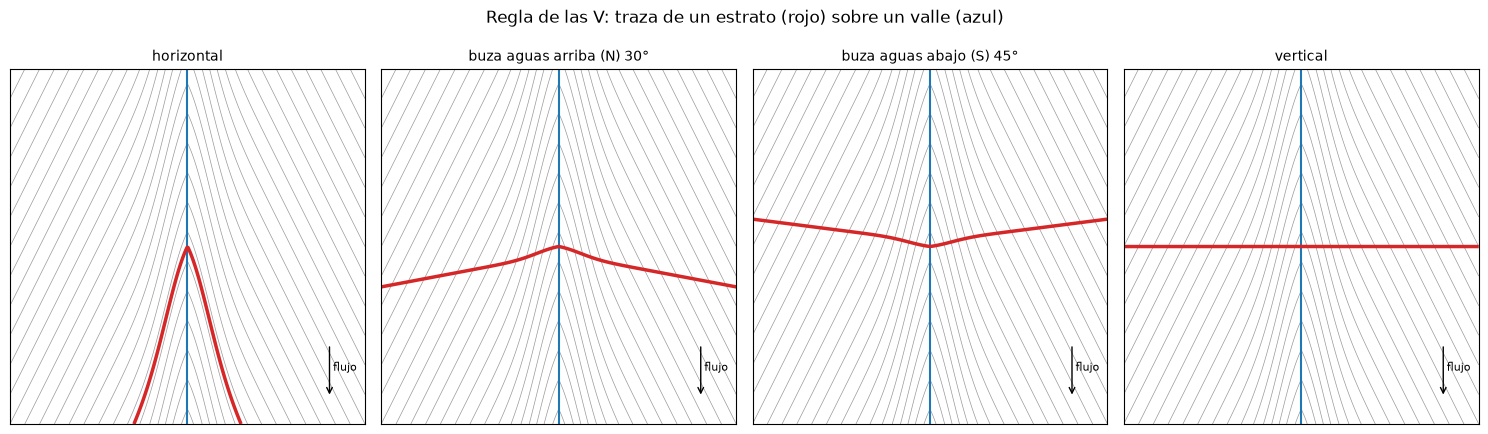

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100

xg, yg = np.meshgrid(np.linspace(-1000, 1000, 400), np.linspace(0, 2000, 400))
z = 0.06 * yg + 0.12 * np.abs(xg) - 25 * np.exp(-xg**2 / 3e4) + 1000      # valle que drena hacia el sur (y = 0)
casos = [('horizontal', 0, None), ('buza aguas arriba (N) 30°', 30, 0), ('buza aguas abajo (S) 45°', 45, 180), ('vertical', 89.9, 0)]
fig, axs = plt.subplots(1, 4, figsize=(15, 4.6))
for ax, (nom, buz, dir_buz) in zip(axs, casos):
    ax.contour(xg, yg, z, levels=np.arange(900, 1300, 10), colors='0.6', linewidths=0.5)
    ax.plot([0, 0], [0, 2000], color='tab:blue', lw=1.5)
    if buz == 0:
        plano = np.full_like(z, 1035.0)
    else:
        az = np.radians(dir_buz)
        nx, ny = np.sin(az), np.cos(az)                      # vector horizontal en la dirección de buzamiento
        plano = 1035 - np.tan(np.radians(buz)) * ((xg - 0) * nx + (yg - 1000) * ny)
    ax.contour(xg, yg, z - plano, levels=[0], colors='tab:red', linewidths=2.5)
    ax.set_title(nom, fontsize=10); ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    ax.annotate('', xy=(800, 150), xytext=(800, 450), arrowprops=dict(arrowstyle='->'))
    ax.text(820, 300, 'flujo', fontsize=8)
plt.suptitle('Regla de las V: traza de un estrato (rojo) sobre un valle (azul)', y=0.98)
plt.tight_layout(); plt.show()

## Medición del buzamiento en el modelo estereoscópico

La exageración vertical del modelo estereoscópico hace que los buzamientos se vean más fuertes de lo que son. Si $\mathrm{EV}$ es la exageración vertical, el buzamiento aparente $\delta'$ que se percibe se relaciona con el real $\delta$ por

$$\tan \delta' = \mathrm{EV} \cdot \tan \delta.$$

Con una exageración de 3, una capa que buza 10° parece buzar 28°, y una de 30° parece de 60°. Por eso las estimaciones visuales se corrigen con esta relación, o, mejor, el buzamiento se calcula a partir de mediciones de altura con la barra de paralaje. La figura muestra la relación para varias exageraciones.

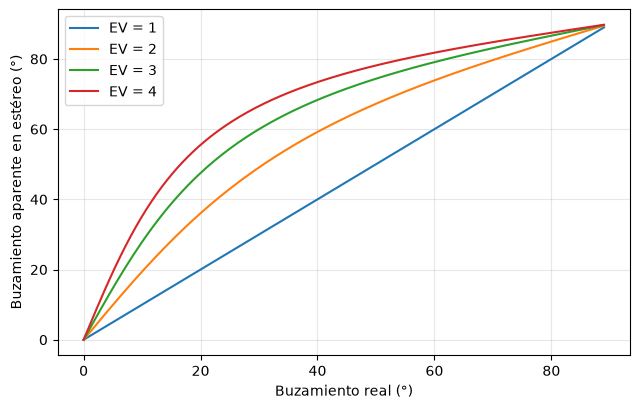

Buzamiento aparente 20° con EV = 3 -> real 6.9°
Buzamiento aparente 35° con EV = 3 -> real 13.1°
Buzamiento aparente 50° con EV = 3 -> real 21.7°


In [2]:
d = np.linspace(0, 89, 200)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for ev in [1, 2, 3, 4]:
    ax.plot(d, np.degrees(np.arctan(ev * np.tan(np.radians(d)))), label=f'EV = {ev}')
ax.set_xlabel('Buzamiento real (°)'); ax.set_ylabel('Buzamiento aparente en estéreo (°)')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
for ap in [20, 35, 50]:
    print(f'Buzamiento aparente {ap}° con EV = 3 -> real {np.degrees(np.arctan(np.tan(np.radians(ap))/3)):.1f}°')

## El problema de los tres puntos

Cuando un contacto o un estrato se puede seguir sobre el modelo estereoscópico, basta con tres puntos de su traza, con sus coordenadas en el mapa y sus elevaciones (medidas con paralaje o leídas en un modelo de elevación), para calcular la orientación del plano. El vector normal al plano es el producto vectorial de dos vectores contenidos en él; de su componente vertical sale el buzamiento y de su proyección horizontal la dirección de buzamiento. La celda siguiente resuelve el problema de forma general y lo verifica con un plano conocido.

In [3]:
def tres_puntos(p1, p2, p3):
    """Puntos (este, norte, elevación). Devuelve (dirección de buzamiento, buzamiento) en grados."""
    p1, p2, p3 = map(np.asarray, (p1, p2, p3))
    nrm = np.cross(p2 - p1, p3 - p1)
    if nrm[2] < 0:
        nrm = -nrm
    buz = np.degrees(np.arccos(nrm[2] / np.linalg.norm(nrm)))
    dir_buz = np.degrees(np.arctan2(nrm[0], nrm[1])) % 360
    return dir_buz, buz

# verificación con un plano que buza 25° hacia el azimut 120°
az, b = np.radians(120), np.radians(25)
plano = lambda e, n: 1500 - np.tan(b) * (e * np.sin(az) + n * np.cos(az))
pts = [(e, n, plano(e, n)) for e, n in [(0, 0), (800, 150), (300, 900)]]
for p in pts:
    print(f'  E = {p[0]:6.0f}  N = {p[1]:6.0f}  z = {p[2]:7.1f}')
db, bz = tres_puntos(*pts)
print(f'Orientación calculada: {db:05.1f}/{bz:.1f} (dirección de buzamiento/buzamiento)')

# con errores de 3 m en la elevación, típicos de la fotogrametría convencional
rng = np.random.default_rng(0)
res = np.array([tres_puntos(*[(e, n, zz + rng.normal(0, 3)) for e, n, zz in pts]) for _ in range(2000)])
print(f'Con errores de 3 m en z: dirección {res[:,0].mean():.1f} ± {res[:,0].std():.1f}°, buzamiento {res[:,1].mean():.1f} ± {res[:,1].std():.1f}°')

  E =      0  N =      0  z =  1500.0
  E =    800  N =    150  z =  1211.9
  E =    300  N =    900  z =  1588.7
Orientación calculada: 120.0/25.0 (dirección de buzamiento/buzamiento)
Con errores de 3 m en z: dirección 120.0 ± 0.6°, buzamiento 25.0 ± 0.2°


## Del modelo estereoscópico al mapa

El mapa fotogeológico final combina las unidades litológicas, los contactos (seguros o inferidos), los rumbos y buzamientos medidos o estimados, los ejes de pliegues, las fallas y los lineamientos. Como las fotos tienen deformaciones, la interpretación se transfiere al mapa base con puntos de control comunes, o se digitaliza directamente sobre ortofotos o en un entorno de estereoscopia digital. En el trabajo final del curso se elaboran un mapa fotogeomorfológico con sus procesos morfodinámicos y un mapa fotogeológico con sus estructuras, que luego se verifican en la salida de campo.

## Para profundizar

{cite:t}`ray1960` es la referencia clásica de la fotogeología, con ejemplos de cada tipo de roca y estructura. La guía de {cite:t}`gutierrez` desarrolla la regla de las V y la medición de buzamientos, y el capítulo 8 de {cite}`lillesand2015` muestra aplicaciones geológicas con imágenes de distintos sensores.